In [ ]:
import os
import pandas as pd

# Path to the mapping file (CSV) that has two columns: "team" and "txt_filename"
mapping_file = "mapping.csv"

# Folder containing the original files
input_folder = "/Users/aditya/leaderboard_analysis/output/"   # update this path to your folder with files
# Folder where renamed files will be placed (can be the same as input_folder)
output_folder = "/Users/aditya/leaderboard_analysis/output_name_corrected/" # update this path as needed

# Read the mapping file
mapping_df = pd.read_csv(mapping_file)

# Ensure output folder exists
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Iterate over each row in the mapping file
for idx, row in mapping_df.iterrows():
    team = row["team"].strip().lower()
    orig_filename = row["txt_filename"].strip()
    
    # Skip if mapping is "NA" or blank in the file name column
    if orig_filename.upper() == "NA" or orig_filename == "":
        print(f"Skipping team '{team}' as no file is mapped.")
        continue
    
    # Full paths for original and new file names
    orig_path = os.path.join(input_folder, orig_filename)
    new_filename = f"output_{team}.txt"
    new_path = os.path.join(output_folder, new_filename)
    
    if os.path.exists(orig_path):
        os.rename(orig_path, new_path)
        print(f"Renamed '{orig_filename}' to '{new_filename}'.")
    else:
        print(f"File '{orig_filename}' not found in '{input_folder}'.")


File 'output_https___github_com_sara_hrad_2024_sepsis_challenge_data_lifesaver_git_main.txt' not found in '/Users/aditya/leaderboard_analysis/output/'.
File 'output_https___github_com_SAStrutz_BadgerPediatricSepsisChallenge_git_main.txt' not found in '/Users/aditya/leaderboard_analysis/output/'.
File 'output_https___github_com_CasualJon_PSDC_Prelim_git_master.txt' not found in '/Users/aditya/leaderboard_analysis/output/'.
Renamed 'output_https___github_com_part_cw_2024_psdc_submission_git_main.txt' to 'output_ubcdigitalhealthinnovationlab.txt'.
File 'output_https___github_com_Darjallo_Sepsis_challenge_git_main.txt' not found in '/Users/aditya/leaderboard_analysis/output/'.
File 'outputs_OHSU.txt' not found in '/Users/aditya/leaderboard_analysis/output/'.
File 'output_https___github_com_autonlab_pediatric_sepsis_data_challenge_git_master.txt' not found in '/Users/aditya/leaderboard_analysis/output/'.
File 'outputs_TeamAims.txt' not found in '/Users/aditya/leaderboard_analysis/output/'.


In [3]:
import os
import csv
import re
import numpy as np
import pandas as pd
# ---------------------------
# Step 1: Extract Predicted Probability Columns from each file
# ---------------------------
def extract_probability_column(filepath):
    """
    Extract the predicted probability column from a file.
    The file is expected to have a header:
    PatientID|PredictedProbability|PredictedBinary
    """
    probabilities = []
    with open(filepath, 'r') as f:
        header = f.readline()  # Skip header
        for line in f:
            parts = line.strip().split('|')
            if len(parts) >= 2:
                try:
                    probabilities.append(float(parts[1]))
                except ValueError:
                    continue
    return probabilities

def save_combined_probabilities(combined_data, output_csv):
    """
    Save the combined data (list of rows, each starting with the team name)
    to a CSV file.
    """
    with open(output_csv, 'w', newline='') as f:
        writer = csv.writer(f)
        if combined_data:
            # Build header: "Team", then Prob_1, Prob_2, ...
            num_probs = len(combined_data[0]) - 1
            header = ["Team"] + [f"Prob_{i+1}" for i in range(num_probs)]
            writer.writerow(header)
        for row in combined_data:
            writer.writerow(row)

# Folder containing the output files (adjust if needed)
evaluate_folder = "/Users/aditya/leaderboard_analysis/output_name_corrected/"

# List all files in the evaluate folder that end with "output.txt"
team_files = [f for f in os.listdir(evaluate_folder) if f.endswith(".txt")]

combined_data = []  # Each row: [team_name, probability1, probability2, ...]
for team_file in team_files:
    filepath = os.path.join(evaluate_folder, team_file)
    probs = extract_probability_column(filepath)
    # Use the full file name (without extension) as the team name.
    team_name = os.path.splitext(team_file)[0]
    row = [team_name] + probs
    combined_data.append(row)

evaluate_combin = "/Users/aditya/leaderboard_analysis/"
# Save the combined probabilities to CSV.
combined_csv_path = os.path.join(evaluate_combin, "combined_probabilities.csv")
save_combined_probabilities(combined_data, combined_csv_path)
print("Combined probabilities saved to:", combined_csv_path)



Combined probabilities saved to: /Users/aditya/leaderboard_analysis/combined_probabilities.csv


Combined probabilities data:
               Team    Prob_1    Prob_2    Prob_3    Prob_4    Prob_5  \
0       output_ohsu  0.000528  0.001638  0.004320  0.000269  0.003887   
1   output_epiphany  0.002702  0.003399  0.000639  0.001102  0.004700   
2  output_teamsimba  0.018781  0.041896  0.029191  0.016097  0.021691   
3   output_datakite  0.960087  0.960087  0.923505  0.962162  0.962786   
4       output_help  0.000000  0.000000  0.013333  0.006667  0.006667   

     Prob_6    Prob_7    Prob_8    Prob_9  ...  Prob_1142  Prob_1143  \
0  0.001716  0.001172  0.007201  0.006202  ...   0.000377   0.013121   
1  0.004680  0.002684  0.160219  0.006242  ...   0.001056   0.008157   
2  0.012360  0.021628  0.029988  0.027450  ...   0.009121   0.043665   
3  0.920806  0.960087  0.962786  0.960087  ...   0.920806   0.962786   
4  0.000000  0.000000  0.153333  0.040000  ...   0.000000   0.020000   

   Prob_1144  Prob_1145  Prob_1146  Prob_1147  Prob_1148  Prob_1149  \
0   0.156861   0.007529   0.

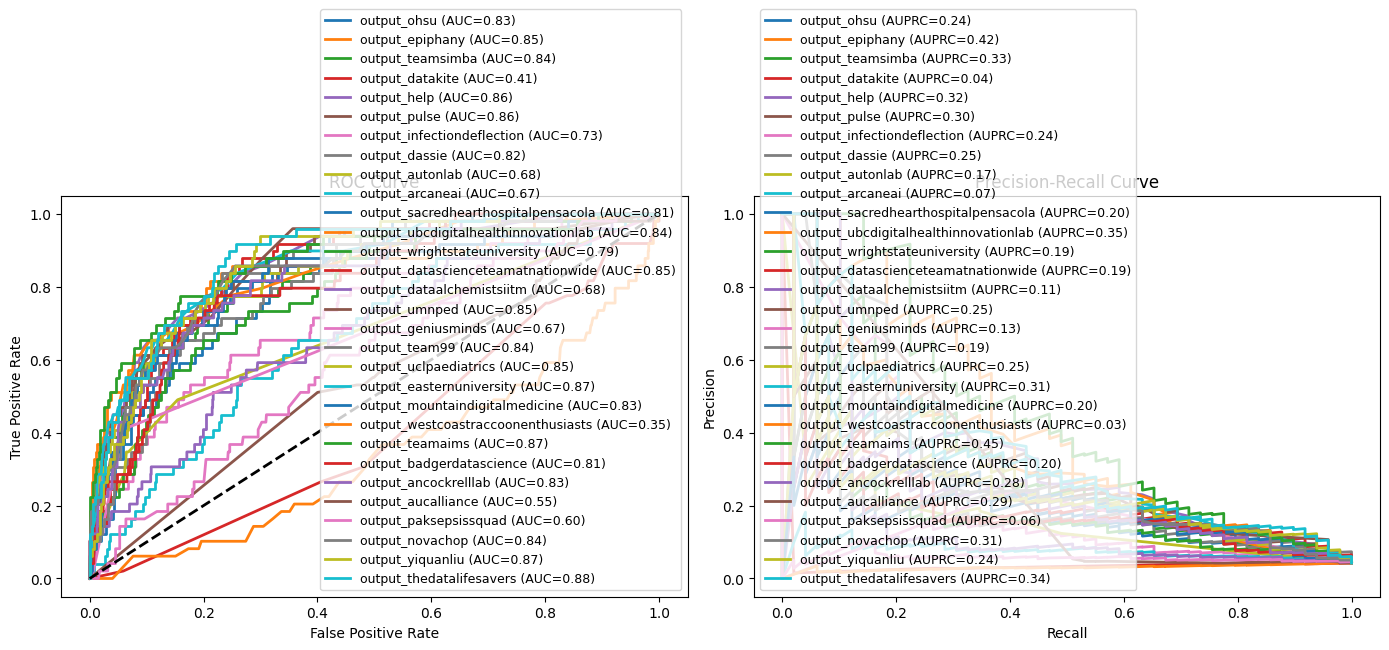

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# ---------------------------
# Load Combined Probabilities Data and Ground Truth Labels
# ---------------------------
# Path to the combined probabilities CSV file.
combined_csv = os.path.join(evaluate_combin, "combined_probabilities.csv")
df_combined = pd.read_csv(combined_csv)
print("Combined probabilities data:")
print(df_combined.head())

# Load ground truth labels (assumes column "inhospital mortality" exists).
labels_csv = "/Users/aditya/Example/labels_.csv"
df_labels = pd.read_csv(labels_csv)
if "inhospital_mortality" not in df_labels.columns:
    raise ValueError("Expected column 'inhospital_mortality' not found in labels.csv")
    
# Extract ground truth labels as a numpy array.
ground_truth = df_labels["inhospital_mortality"].values

# ---------------------------
# Plot ROC and PRC Curves
# ---------------------------
plt.figure(figsize=(14, 6))

# Subplot 1: ROC Curves
plt.subplot(1, 2, 1)
for idx, row in df_combined.iterrows():
    team = row["Team"]
    # Extract all probability values (skipping the 'Team' column)
    prob_vector = row.drop("Team").dropna().tolist()
    
    # Check if the length matches the ground truth
    if len(prob_vector) != len(ground_truth):
        print(f"Skipping team '{team}': {len(prob_vector)} predictions vs {len(ground_truth)} labels")
        continue
    
    # Compute ROC curve and AUC score
    fpr, tpr, _ = roc_curve(ground_truth, prob_vector)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{team} (AUC={roc_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--', lw=2)  # Diagonal line for random classifier.
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right", fontsize=9)

# Subplot 2: Precision-Recall Curves
plt.subplot(1, 2, 2)
for idx, row in df_combined.iterrows():
    team = row["Team"]
    prob_vector = row.drop("Team").dropna().tolist()
    
    if len(prob_vector) != len(ground_truth):
        print(f"Skipping team '{team}': {len(prob_vector)} predictions vs {len(ground_truth)} labels")
        continue
    
    # Compute Precision-Recall curve and AUPRC score
    precision, recall, _ = precision_recall_curve(ground_truth, prob_vector)
    prc_auc = auc(recall, precision)
    plt.plot(recall, precision, lw=2, label=f"{team} (AUPRC={prc_auc:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()


In [5]:
import os
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, auc

# ---------------------------
# Helper Functions for Thresholds
# ---------------------------
def compute_threshold_sensitivity(prob_vector, ground_truth, sensitivity_min=0.8):
    """
    Compute the optimal threshold such that sensitivity (TPR) is at least sensitivity_min.
    Among thresholds achieving this, choose the one with the lowest FPR.
    
    Returns:
        (optimal_threshold, sensitivity, specificity)
    """
    fpr, tpr, thresholds = roc_curve(ground_truth, prob_vector)
    valid_idx = np.where(tpr >= sensitivity_min)[0]
    if len(valid_idx) == 0:
        return None, None, None
    best_idx = valid_idx[np.argmin(fpr[valid_idx])]
    optimal_threshold = thresholds[best_idx]
    sensitivity = tpr[best_idx]
    specificity = 1 - fpr[best_idx]
    return optimal_threshold, sensitivity, specificity

def compute_threshold_youden(prob_vector, ground_truth):
    """
    Compute the optimal threshold by maximizing Youden's index (sensitivity - FPR).
    
    Returns:
        (optimal_threshold, sensitivity, specificity)
    """
    fpr, tpr, thresholds = roc_curve(ground_truth, prob_vector)
    youden_index = tpr - fpr
    best_idx = np.argmax(youden_index)
    optimal_threshold = thresholds[best_idx]
    sensitivity = tpr[best_idx]
    specificity = 1 - fpr[best_idx]
    return optimal_threshold, sensitivity, specificity

def compute_threshold_f1(prob_vector, ground_truth):
    """
    Compute the optimal threshold by maximizing the F1 score.
    
    Returns:
        (optimal_threshold, sensitivity, specificity)
    """
    thresholds = np.linspace(0, 1, 101)
    best_f1 = -1
    best_thresh = None
    best_sens = None
    best_spec = None
    
    for thresh in thresholds:
        predictions = (np.array(prob_vector) >= thresh).astype(int)
        TP = np.sum((predictions == 1) & (np.array(ground_truth) == 1))
        FP = np.sum((predictions == 1) & (np.array(ground_truth) == 0))
        FN = np.sum((predictions == 0) & (np.array(ground_truth) == 1))
        TN = np.sum((predictions == 0) & (np.array(ground_truth) == 0))
        
        sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0
        specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
        f1 = 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) > 0 else 0
        
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = thresh
            best_sens = sensitivity
            best_spec = specificity
    return best_thresh, best_sens, best_spec

def compute_f1(tp, fp, fn):
    """Compute the F1 score from confusion matrix entries."""
    denominator = 2 * tp + fp + fn
    return 2 * tp / denominator if denominator != 0 else 0.0

# ---------------------------
# Additional Metrics Functions
# ---------------------------
def calculate_net_benefit(y_true, y_pred, threshold):
    """
    Calculate Net Benefit at the given threshold.
    
    NB = (TP/N) - (threshold/(1-threshold)) * (FP/N)
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    TP = np.sum((y_true == 1) & (y_pred >= threshold))
    FP = np.sum((y_true == 0) & (y_pred >= threshold))
    n = len(y_true)
    return (TP / n) - ((threshold / (1 - threshold)) * (FP / n))

def calculate_ece(probs, labels, n_bins=10):
    """
    Calculate the Estimated Calibration Error (ECE).
    """
    probs = np.array(probs)
    labels = np.array(labels)
    bin_edges = np.linspace(0, 1, n_bins+1)
    ece = 0
    for i in range(n_bins):
        bin_mask = (probs > bin_edges[i]) & (probs <= bin_edges[i+1])
        bin_size = np.sum(bin_mask)
        if bin_size > 0:
            bin_acc = np.mean(labels[bin_mask])
            bin_conf = np.mean(probs[bin_mask])
            ece += bin_size * np.abs(bin_acc - bin_conf) / len(probs)
    return ece

# ---------------------------
# Function to Evaluate All Methods
# ---------------------------
def evaluate_team_all_methods(prob_vector, ground_truth):
    """
    Compute evaluation metrics at the optimal threshold using three methods:
     - Sensitivity method: Ensuring sensitivity >= 0.8.
     - Youden's index method.
     - F1 score method.
     
    Also computes AUC, AUPRC, and ECE (threshold independent).
    
    Returns a dictionary containing:
      - For each method: Optimal Threshold, Sensitivity, Specificity, F1, TP, FP, FN, TN, and Net Benefit.
      - Global metrics: AUC, AUPRC, and ECE.
    """
    # Method 1: Sensitivity method (ensure sensitivity >= 0.8)
    threshold_sen, sens_sen, spec_sen = compute_threshold_sensitivity(prob_vector, ground_truth, sensitivity_min=0.8)
    if threshold_sen is not None:
        predictions_sen = (np.array(prob_vector) >= threshold_sen).astype(int)
        TP_sen = np.sum((predictions_sen == 1) & (np.array(ground_truth) == 1))
        FP_sen = np.sum((predictions_sen == 1) & (np.array(ground_truth) == 0))
        FN_sen = np.sum((predictions_sen == 0) & (np.array(ground_truth) == 1))
        TN_sen = np.sum((predictions_sen == 0) & (np.array(ground_truth) == 0))
        F1_sen = compute_f1(TP_sen, FP_sen, FN_sen)
    else:
        TP_sen = FP_sen = FN_sen = TN_sen = F1_sen = None

    # Method 2: Youden method
    threshold_youden, sens_youden, spec_youden = compute_threshold_youden(prob_vector, ground_truth)
    predictions_youden = (np.array(prob_vector) >= threshold_youden).astype(int)
    TP_youden = np.sum((predictions_youden == 1) & (np.array(ground_truth) == 1))
    FP_youden = np.sum((predictions_youden == 1) & (np.array(ground_truth) == 0))
    FN_youden = np.sum((predictions_youden == 0) & (np.array(ground_truth) == 1))
    TN_youden = np.sum((predictions_youden == 0) & (np.array(ground_truth) == 0))
    F1_youden = compute_f1(TP_youden, FP_youden, FN_youden)
    
    # Method 3: F1 method
    threshold_f1, sens_f1, spec_f1 = compute_threshold_f1(prob_vector, ground_truth)
    predictions_f1 = (np.array(prob_vector) >= threshold_f1).astype(int)
    TP_f1 = np.sum((predictions_f1 == 1) & (np.array(ground_truth) == 1))
    FP_f1 = np.sum((predictions_f1 == 1) & (np.array(ground_truth) == 0))
    FN_f1 = np.sum((predictions_f1 == 0) & (np.array(ground_truth) == 1))
    TN_f1 = np.sum((predictions_f1 == 0) & (np.array(ground_truth) == 0))
    F1_f1 = compute_f1(TP_f1, FP_f1, FN_f1)
    
    # Global metrics (threshold independent)
    auc_score = roc_auc_score(ground_truth, prob_vector)
    precision, recall, _ = precision_recall_curve(ground_truth, prob_vector)
    auprc_score = auc(recall, precision)
    ece_score = calculate_ece(prob_vector, ground_truth)
    
    net_benefit_sen = calculate_net_benefit(ground_truth, prob_vector, threshold_sen) if threshold_sen is not None else None
    net_benefit_youden = calculate_net_benefit(ground_truth, prob_vector, threshold_youden)
    net_benefit_f1 = calculate_net_benefit(ground_truth, prob_vector, threshold_f1)
    
    results = {
        "Sensitivity Method": {
            "Optimal Threshold": threshold_sen,
            "Sensitivity": sens_sen,
            "Specificity": spec_sen,
            "F1": F1_sen,
            "TP": TP_sen,
            "FP": FP_sen,
            "FN": FN_sen,
            "TN": TN_sen,
            "Net Benefit": net_benefit_sen
        },
        "Youden Method": {
            "Optimal Threshold": threshold_youden,
            "Sensitivity": sens_youden,
            "Specificity": spec_youden,
            "F1": F1_youden,
            "TP": TP_youden,
            "FP": FP_youden,
            "FN": FN_youden,
            "TN": TN_youden,
            "Net Benefit": net_benefit_youden
        },
        "F1 Method": {
            "Optimal Threshold": threshold_f1,
            "Sensitivity": sens_f1,
            "Specificity": spec_f1,
            "F1": F1_f1,
            "TP": TP_f1,
            "FP": FP_f1,
            "FN": FN_f1,
            "TN": TN_f1,
            "Net Benefit": net_benefit_f1
        },
        "AUC": auc_score,
        "AUPRC": auprc_score,
        "ECE": ece_score
    }
    
    return results




In [6]:
# ---------------------------
# Main Processing: Compute Metrics for Each Team
# ---------------------------

# Load combined probabilities CSV.
combined_csv = os.path.join(evaluate_combin, "combined_probabilities.csv")
df_combined = pd.read_csv(combined_csv)

# Load ground truth labels (assumes a column "inhospital mortality").
labels_csv = "/Users/aditya/Example/labels_.csv"
df_labels = pd.read_csv(labels_csv)
if "inhospital_mortality" not in df_labels.columns:
    raise ValueError("Expected column 'inhospital mortality' in labels.csv")
ground_truth = df_labels["inhospital_mortality"].values

# ---------------------------
# Pipeline: Evaluate Each Team's Predictions Using All Methods and Save Separately
# ---------------------------
# Assume df_combined is your DataFrame with team predictions, where one column "Team" contains team names,
# and the remaining columns are predicted probabilities for each patient.
# Also assume that ground_truth is a list or array of true binary labels.
results_sen = []
results_youden = []
results_f1 = []

# Loop through each team in df_combined
for idx, row in df_combined.iterrows():
    team = row["Team"]
    prob_vector = row.drop("Team").dropna().tolist()
    
    if len(prob_vector) != len(ground_truth):
        print(f"Skipping team '{team}': {len(prob_vector)} predictions vs {len(ground_truth)} labels")
        continue
    
    metrics = evaluate_team_all_methods(prob_vector, ground_truth)
    if metrics is None:
        print(f"Team '{team}': no valid threshold found.")
        continue
    
    # Separate dictionaries for each method
    res_sen = metrics["Sensitivity Method"]
    res_youden = metrics["Youden Method"]
    res_f1 = metrics["F1 Method"]
    
    # Add global metrics and team name to each dictionary
    for res in (res_sen, res_youden, res_f1):
        res["AUC"] = metrics["AUC"]
        res["AUPRC"] = metrics["AUPRC"]
        res["ECE"] = metrics["ECE"]
        res["Team"] = team
    
    results_sen.append(res_sen)
    results_youden.append(res_youden)
    results_f1.append(res_f1)

# Create separate DataFrames for each method.
df_sen = pd.DataFrame(results_sen)
df_youden = pd.DataFrame(results_youden)
df_f1 = pd.DataFrame(results_f1)

# Save each DataFrame to separate CSV files.
output_folder = "optimal_threshold_results"
os.makedirs(output_folder, exist_ok=True)

df_sen.to_csv(os.path.join(output_folder, "evaluation_metrics_sensitivity_method.csv"), index=False)
df_youden.to_csv(os.path.join(output_folder, "evaluation_metrics_youden_method.csv"), index=False)
df_f1.to_csv(os.path.join(output_folder, "evaluation_metrics_f1_method.csv"), index=False)

print("Saved evaluation metrics for all methods separately.")

Saved evaluation metrics for all methods separately.


/var/folders/nt/cn_nn5sj2ld2vf84v9rxyh1m0000gn/T/ipykernel_56321/2440562439.py:92: RuntimeWarning: invalid value encountered in scalar divide
  return (TP / n) - ((threshold / (1 - threshold)) * (FP / n))


In [1]:
import os
import pandas as pd
import numpy as np
import plotly.express as px
import umap
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc

# ---------------------------
# Helper functions for evaluation
# ---------------------------
def calculate_net_benefit(y_true, y_pred, threshold=0.5):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    tp = np.sum((y_true == 1) & (y_pred >= threshold))
    fp = np.sum((y_true == 0) & (y_pred >= threshold))
    n = len(y_true)
    return (tp / n) - ((threshold / (1 - threshold)) * (fp / n))

def calculate_ece(probs, labels, n_bins=10):
    probs = np.array(probs)
    labels = np.array(labels)
    bin_edges = np.linspace(0, 1, n_bins+1)
    ece = 0
    for i in range(n_bins):
        bin_mask = (probs > bin_edges[i]) & (probs <= bin_edges[i+1])
        bin_size = np.sum(bin_mask)
        if bin_size > 0:
            bin_acc = np.mean(labels[bin_mask])
            bin_conf = np.mean(probs[bin_mask])
            ece += bin_size * np.abs(bin_acc - bin_conf) / len(probs)
    return ece

def compute_f1(tp, fp, fn):
    """Compute the F1 score from confusion matrix entries."""
    denominator = 2 * tp + fp + fn
    return 2 * tp / denominator if denominator != 0 else 0.0

def evaluate_probabilities(prob_vector, labels, threshold=0.5):
    """
    Evaluate a probability vector against ground truth labels and compute evaluation metrics,
    including AUC, AUPRC, net benefit, ECE, and F1.
    """
    prob_vector = np.array(prob_vector, dtype=float)
    labels = np.array(labels, dtype=int)
    
    auc_score = roc_auc_score(labels, prob_vector)
    precision, recall, _ = precision_recall_curve(labels, prob_vector)
    auprc_score = auc(recall, precision)
    
    net_benefit = calculate_net_benefit(labels, prob_vector, threshold)
    ece_score = calculate_ece(prob_vector, labels, n_bins=10)
    
    predictions = (prob_vector >= threshold).astype(int)
    tn = np.sum((labels == 0) & (predictions == 0))
    fp = np.sum((labels == 0) & (predictions == 1))
    fn = np.sum((labels == 1) & (predictions == 0))
    tp = np.sum((labels == 1) & (predictions == 1))
    f1_score = compute_f1(tp, fp, fn)
    
    return {
        "AUC": auc_score,
        "AUPRC": auprc_score,
        "Net Benefit": net_benefit,
        "ECE": ece_score,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "F1": f1_score
    }

# ---------------------------
# Clustering and interactive plotting on evaluated metrics
# ---------------------------
# Load evaluated metrics CSV.
# It is assumed that the CSV has been generated from your evaluation step
# and contains at least the following columns: "Team", "AUC", "AUPRC", "Net Benefit", "ECE", "F1"
eval_csv = os.path.join("optimal_threshold_results", "evaluation_metrics_sensitivity_method.csv")
df_eval = pd.read_csv(eval_csv)
print("Evaluated metrics data:")
print(df_eval.head())

# Select numeric features for clustering. For example, we use AUC, AUPRC, Net Benefit, ECE, and F1.
numeric_cols = ["AUC", "AUPRC", "Net Benefit", "ECE", "F1"]
X_eval = df_eval[numeric_cols].fillna(0).values

# Standardize the features.
scaler = StandardScaler()
X_eval_scaled = scaler.fit_transform(X_eval)

# Apply UMAP to reduce the evaluated metrics to 2 dimensions.
umap_model_eval = umap.UMAP(random_state=42)
embedding_eval = umap_model_eval.fit_transform(X_eval_scaled)

# Perform KMeans clustering on the UMAP embedding.
kmeans_eval = KMeans(n_clusters=3, random_state=42)
clusters_eval = kmeans_eval.fit_predict(embedding_eval)

# Create a DataFrame for Plotly plotting.
df_eval_plot = pd.DataFrame({
    "UMAP1": embedding_eval[:, 0],
    "UMAP2": embedding_eval[:, 1],
    "Cluster": clusters_eval,
    "Team": df_eval["Team"],
    "AUC": df_eval["AUC"],
    "AUPRC": df_eval["AUPRC"],
    "F1": df_eval["F1"]
})

# Plot using Plotly.
# The tooltip will display the Team name, AUC, AUPRC, and F1 score.
fig_eval = px.scatter(
    df_eval_plot,
    x="UMAP1",
    y="UMAP2",
    color="Cluster",
    hover_name="Team",
    hover_data=["AUC", "AUPRC", "F1"],
    title="UMAP & KMeans Clustering on Evaluated Metrics"
)
fig_eval.show()


/Users/aditya/miniconda3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Evaluated metrics data:
   Optimal Threshold  Sensitivity  Specificity        F1  TP   FP  FN   TN  \
0           0.007312     0.816327     0.683303  0.182648  40  349   9  753   
1           0.011308     0.816327     0.789474  0.249221  40  232   9  870   
2           0.037842     0.816327     0.661525  0.173160  40  373   9  729   
3           0.920002     0.816327     0.124319  0.075901  40  965   9  137   
4           0.053333     0.836735     0.732305  0.212987  41  295   8  807   

   Net Benefit       AUC     AUPRC       ECE              Team  
0     0.032519  0.829809  0.235732  0.026223       output_ohsu  
1     0.032447  0.845383  0.417397  0.023333   output_epiphany  
2     0.022007  0.840087  0.325013  0.012143  output_teamsimba  
3    -9.607126  0.411423  0.041977  0.909646   output_datakite  
4     0.021182  0.863013  0.318538  0.012818       output_help  


/Users/aditya/miniconda3/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/aditya/miniconda3/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
